# 9. Tracking data II: real DSN data

> Process the real OSIRIS-REx tracking pass of June 8, 2018: read the converted TRK-2-34 file, set up the precise light-time measurement models with their auxiliary data and media corrections, edit gross outliers, validate the models against the flight team's reconstructed trajectory, and fit the pass.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [5. The filter's measurement model](05_filter_measurements.ipynb), [6. First OD solution](06_first_od_solution.ipynb) &nbsp;·&nbsp; **Uses:** the real tracking and media-correction files in the tutorial data (no earlier chapter outputs)

Chapters [3](03_tracking_data.ipynb)–[8](08_estimating_more.ipynb) used ideal measurement models: instantaneous geometry, no light time, no media, simulated noise. Real DSN observables are defined by the hardware: a ramped uplink frequency, a round-trip light time with relativistic corrections, a spacecraft transponder with a fixed turnaround ratio, a count interval, station calibrations, and the troposphere and ionosphere along the path. Scarabaeus models these in `DopplerReal` and `SequentialRangingReal`. This chapter sets them up for one DSN pass and checks them against the flight reconstruction, which plays the role of the best available trajectory ("predict").

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> Open before release: the first 15 Doppler points (section 4), the ranging offset (section 4), and replacing <code>trk234.py</code> with a library loader. Ranging joins the fit once its offset is understood.
</div>

## Setup

The scenario kernels, units and spacecraft from [`scenario.py`](scenario.py) and the paths to the real tracking and media-correction files.

`trk234` is a small module in this folder that builds the auxiliary data the real measurement models need from the tracking file (section 2). It stands in for a library loader that does not exist yet.

In [1]:
import shutil
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

from scenario import kg, km, m, sec, J2000, sun, orex_flight, reference, planets

import trk234  # 🔵 TODO: tutorial-side loader for TRK-2-34 auxiliary data; to be upstreamed into Scarabaeus

out = Path("outputs/09_real_dsn_data")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

data_dir = Path("../supplementary/supp_data/measurements")
trk_file = data_dir / "radiometric/orex_beno_2018_159_054533_2018_159_104001_35.json"
media_dir = data_dir / "media_correction"
tropo_seasonal_file = media_dir / "1972_001_2048_001_tro_modified.json"
if not (trk_file.exists() and tropo_seasonal_file.exists()):
    raise FileNotFoundError("Tutorial data not found: download it as described in the README (Running, step 1).")

hr = scb.Units.get_units(["hr"])


## 1. The tracking file

DSN tracking data are distributed in the TRK-2-34 format. The tutorial data include one pass, converted to the JSON layout from [chapter 3](03_tracking_data.ipynb): one block per observable (two-way Doppler and sequential ranging), and auxiliary blocks (*SFDU* records) with ramp tables, count times, transponder parameters, calibrations and delays.

In [2]:
trk = trk234.load(trk_file)
station = scb.GroundStation(trk234.station_name(trk))

print(f"station: {station.name}")
for block, content in trk.items():
    if isinstance(content, dict):
        n = len(next(iter(content.values())))
        print(f"  {block:12s} {n:6d} records   fields: {', '.join(list(content)[:6])}{', ...' if len(content) > 6 else ''}")

station: DSS-35
  2W_doppler      217 records   fields: year, doy, sec, meas, spice_id, outlier_flag, ...
  2W_sranging      99 records   fields: year, doy, sec, meas, spice_id, outlier_flag
  aux_SFDU_9       37 records   fields: year, doy, sec, ramp_freq, ramp_rate, ramp_type
  aux_SFDU_0    17664 records   fields: year, doy, sec, ramp_freq, ramp_rate, ramp_type
  aux_SFDU_7       99 records   fields: year, doy, sec, rng_modulo, exc_scalar_num, exc_scalar_den, ...
  aux_SFDU_16     217 records   fields: year, doy, sec, Tc, M2_num, M2_den, ...
  aux_SFDU_2    12356 records   fields: year, doy, sec, ul_zheight_corr, ul_cal_freq, transmit_time_tag_delay, ...
  aux_SFDU_3       99 records   fields: year, doy, sec, dl_zheight_corr, rcv_time_tag_delay, outlier_flag


The pass was tracked by DSS-35 (Canberra), with 217 two-way Doppler and 99 sequential ranging observations. The ramp records (`aux_SFDU_9`) describe the uplink frequency as a piecewise-linear function of time, which the measurement models integrate over each count interval.

## 2. Real measurement models

The real models need, besides the station and the noise level, the auxiliary data of the pass. `trk234` builds them from the file: count times and turnaround ratio for Doppler, range units and modulus for ranging, the ramp table, calibrations and delays for both. The noise levels are those of the original real-data tutorial.

In [3]:
doppler = scb.DopplerReal("DSS-35 Doppler", station, sigma=scb.ArrayWUnits(1e-3, 1 / sec), meas_bias=0.0,
                          computed_measurements_dict=trk234.doppler_aux_data(trk))
ranging = scb.SequentialRangingReal("DSS-35 ranging", station, sigma=scb.ArrayWUnits(0.5, km / km), meas_bias=0.0,
                                    computed_measurements_dict=trk234.sranging_aux_data(trk))

observed_doppler = doppler.observed_measurements(str(trk_file), meas_name="2W_doppler", units=1 / sec)
observed_ranging = ranging.observed_measurements(str(trk_file), meas_name="2W_sranging", units=km / km)

t_doppler = observed_doppler[0]
print(f"Doppler: {t_doppler.size} observations, {t_doppler[0].to(rep='ISOC')} to {t_doppler[-1].to(rep='ISOC')}")
print(f"ranging: {observed_ranging[0].size} observations")
print("first Doppler values:", observed_doppler[2].quantity[:3])

  5 observation(s) in '2W_sranging' carry the -1 no-data sentinel and were flagged as outliers (indices [0, 1, 2, 3, 4])
Doppler: 217 observations, 2018-06-08T05:56:12.1847 (TDB) to 2018-06-08T10:30:02.1847 (TDB)
ranging: 99 observations
first Doppler values: [-8.4459453e+09 -8.4459453e+09 -8.4459453e+09] [Hz ... Hz]


The Doppler observable is the frequency count reported by the station, about −8.4 GHz here, not a frequency shift; ranging is reported in range units (RU), modulo the ranging code length. Only residuals against a model are informative.

## 3. Media corrections

`MediaCorrections` evaluates tropospheric and ionospheric path delays at each end of the light path. The seasonal troposphere model is always available; non-seasonal troposphere and ionosphere calibrations are looked up for the day of the pass. `trk234.media_corrections` wraps that lookup:

In [4]:
for model, observed in [(doppler, observed_doppler), (ranging, observed_ranging)]:
    model.media_corrections = trk234.media_corrections(station, observed[0][0], str(tropo_seasonal_file),
                                                       str(media_dir), f"{model.name} media")

media = doppler.media_corrections
print("non-seasonal troposphere:", Path(media.tropo_non_seasonal_file_path).name if media.tropo_non_seasonal_file_path else None)
print("ionosphere:              ", media.iono_file_path)

non-seasonal troposphere: 2018_152_2018_182_tro.json
ionosphere:               None


The tutorial data contain a non-seasonal troposphere file covering June 2018 but no ionosphere calibration, so the ionospheric delay is not modeled here.

## 4. Pre-fit residuals against the flight reconstruction

Evaluating both models on the flight team's reconstructed trajectory (SPICE ID `-64`) tests the models and the data together: residuals at the noise level mean the auxiliary data, light-time solution and media corrections are consistent with the reconstruction.

In [5]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
computed_doppler = doppler.computed_measurements(target=orex_flight, epoch_array=t_doppler, noisy=False)[-1]
computed_ranging = ranging.computed_measurements(target=orex_flight, epoch_array=observed_ranging[0], noisy=False)[-1]

In [6]:
oc_doppler = doppler.residuals(observed_doppler[2], computed_doppler).quantity.values
oc_ranging = ranging.residuals(observed_ranging[2], computed_ranging).quantity.values

print(f"Doppler O−C: median {statistics.median(oc_doppler):+.4f} Hz, range of values {min(oc_doppler):.1f} to {max(oc_doppler):.1f} Hz")
print(f"ranging O−C: median {statistics.median(oc_ranging):+.1f} RU")

Doppler O−C: median -0.0008 Hz, range of values -382382.1 to 3681.2 Hz
ranging O−C: median +1684.9 RU


The Doppler median is at the mHz level, but the spread shows gross outliers. Before any fit, real data need a coarse editing step that removes points far outside what the a-priori trajectory allows. Observations whose O − C exceeds 1 Hz (about 18 mm/s in range-rate) are flagged; flags are stored in the `meas_outliers` field of the observations ([chapter 3](03_tracking_data.ipynb)), which the filters respect:

flagged 15 of 217 Doppler observations: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
their O−C [Hz]: [-382382.14, -382358.56, -382335.3, -5980.59, -5977.11, -5973.58, -5970.25, -5966.89, -5963.54, -5960.32, -5957.71, -5955.73, -5954.04, -5951.62, 3681.24]
RMS of the remaining residuals: 3.37 mHz (1.17 mHz without the 4 end-of-pass points beyond 10 mHz)


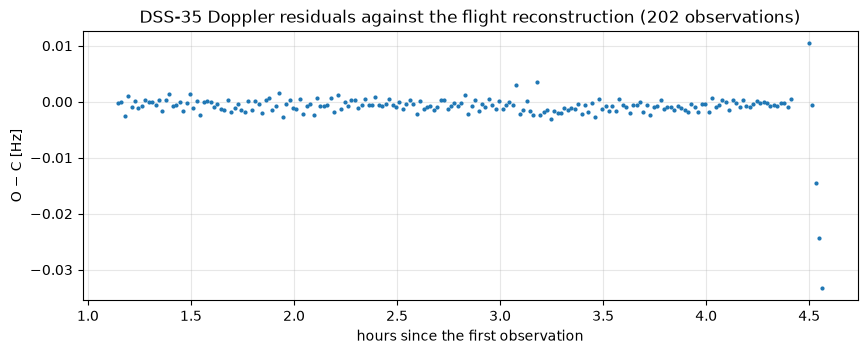

In [7]:
gross = [abs(r) > 1.0 for r in oc_doppler]
observed_doppler = observed_doppler._replace(
    meas_outliers=[1.0 if g else flag for g, flag in zip(gross, observed_doppler.meas_outliers)])

flagged = [i for i, g in enumerate(gross) if g]
print(f"flagged {len(flagged)} of {len(gross)} Doppler observations: {flagged}")
print("their O−C [Hz]:", sorted({round(float(oc_doppler[i]), 2) for i in flagged}))

kept = [i for i, g in enumerate(gross) if not g]
t_hours = (t_doppler - t_doppler[0]).convert_to(hr).values
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot([t_hours[i] for i in kept], [oc_doppler[i] for i in kept], ".", ms=4)
ax.set(xlabel="hours since the first observation", ylabel="O − C [Hz]",
       title=f"DSS-35 Doppler residuals against the flight reconstruction ({len(kept)} observations)")
ax.grid(alpha=0.3)
rms = (sum(oc_doppler[i] ** 2 for i in kept) / len(kept)) ** 0.5
body = [oc_doppler[i] for i in kept if abs(oc_doppler[i]) < 0.01]
print(f"RMS of the remaining residuals: {rms * 1e3:.2f} mHz "
      f"({(sum(r**2 for r in body) / len(body)) ** 0.5 * 1e3:.2f} mHz without the {len(kept) - len(body)} end-of-pass points beyond 10 mHz)")

<div style="border-left:4px solid #ea580c; background:rgba(234,88,12,0.12); padding:6px 10px; border-radius:4px">
🟠 <b>CHECK:</b> The flagged points are the first 15 of the pass, off by −382 kHz, about −5,960 Hz and, for one, +3,681 Hz; possibly before the uplink ramp was stable. Scarabaeus 2.0 flags round trips that start before the first ramp record, and none of these are flagged that way, so the cause is still open. (With Scarabaeus 1.x, one observation every ~7 minutes was also off by 16.75 Hz: a count-interval conversion bug, fixed in 2.0.)
</div>

With those points removed, the real Doppler data agree with the flight reconstruction to about 1.2 mHz RMS, equivalent to about 0.02 mm/s in range-rate, apart from the last four points of the pass, which drift by tens of mHz. This validates the Doppler model chain: auxiliary data, ramp integration, light time and media corrections.

The ranging residuals tell a different story:

ranging O−C: median 1684.9 RU; 94 of 99 observations within ±100 RU of it
spread of those: -0.56 to +0.64 RU around the median


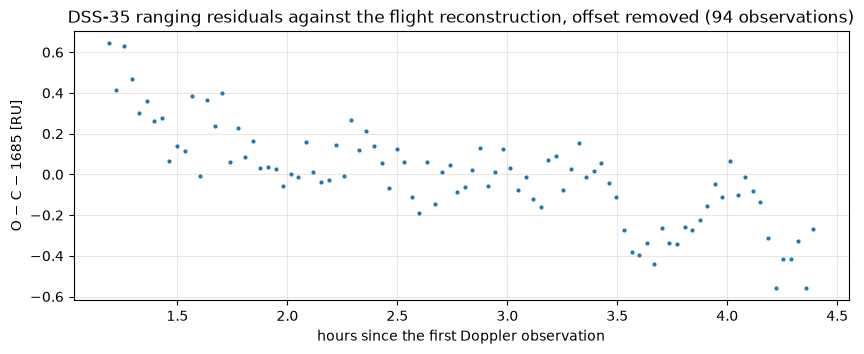

In [8]:
median_ranging = statistics.median(oc_ranging)
near_median = [r for r in oc_ranging if abs(r - median_ranging) < 100]
print(f"ranging O−C: median {median_ranging:.1f} RU; {len(near_median)} of {len(oc_ranging)} observations within ±100 RU of it")
print(f"spread of those: {min(near_median) - median_ranging:+.2f} to {max(near_median) - median_ranging:+.2f} RU around the median")

t_ranging = (observed_ranging[0] - t_doppler[0]).convert_to(hr).values
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot([t for t, r in zip(t_ranging, oc_ranging) if abs(r - median_ranging) < 100],
        [r - median_ranging for r in near_median], ".", ms=4)
ax.set(xlabel="hours since the first Doppler observation", ylabel=f"O − C − {median_ranging:.0f} [RU]",
       title=f"DSS-35 ranging residuals against the flight reconstruction, offset removed ({len(near_median)} observations)")
ax.grid(alpha=0.3)

Around the offset, the residuals are not white noise: they drift by about 1 RU over the three hours, with structure on a scale of an hour. A constant calibration term would remove the offset but not this trend, so part of the ranging mismatch varies along the pass.

<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> Sequential ranging shows a nearly constant offset of about +1,685 RU against the flight reconstruction, while Doppler fits at the noise level (with Scarabaeus 1.x it was −12,386 RU; 2.0 reworked the transponder and electronic delays). A constant offset points to a delay or calibration term rather than the trajectory; the transponder delay used for OSIRIS-REx (<code>trk234.SCFT_TRANSPD_DELAY_RU</code>) is the first suspect. Under investigation; ranging is left out of the fit below. 2.0 adds <code>range_bias_RU</code> partials, so the offset could be estimated as a bias, but that would absorb it, not explain it.
</div>

## 5. Setting up the fit

The orbit determination setup is the one from [chapter 6](06_first_od_solution.ipynb), with two changes for a single pass:

- **A-priori state:** the flight reconstruction at the start of the arc plus a known error of 10 km and 1 cm/s per axis, with a 1σ of 30 km and 3 cm/s per axis.
- **Propagation grid:** a 60-second grid from 04:30 to 11:30 UTC. The real models evaluate the state at transmission and reflection times, not only at the observation time tags, and the arc is padded so that the light-time solution stays inside it.

In [9]:
epochs = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-08T04:30:00"),
                                 scb.SpiceManager.utc2et("2018-06-08T11:30:00"),
                                 dt=scb.ArrayWUnits(60, sec), sys="TDB")

x_flight0 = orex_flight.get_state(epochs[0], reference_frame="J2000", origin="SUN")
r_apriori = x_flight0.quantity[:3] + scb.ArrayWUnits([10.0] * 3, km)
v_apriori = x_flight0.quantity[3:] + scb.ArrayWUnits([0.01] * 3, m / sec).convert_to(km / sec)
state = scb.StateDefinition().position(reference, scb.ArrayWFrame(r_apriori, J2000)).velocity(reference, scb.ArrayWFrame(v_apriori, J2000))

propagator = scb.Propagator(primary_body=reference, state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=state),
                            tspan=epochs,
                            force_models=scb.ForceModelTranslation(reference, third_bodies=planets,
                                                                   cannonball_SRP=True))
P0 = scb.CovarianceMatrix([scb.ArrayWUnits(30.0, km)] * 3 + [scb.ArrayWUnits(0.03, m / sec).convert_to(km / sec)] * 3,
                          epochs[0], from_list=True)
tracking = scb.MeasurementSpec.many(scb.MeasurementSpec(model=doppler, observed_meas=observed_doppler, dataset_name=doppler.name))

## 6. The fit

The filter call is the same as in [chapter 6](06_first_od_solution.ipynb):

In [10]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
srifb = scb.SRIFB(propagator=propagator, measurements=tracking, settings=scb.FilterSettings(initial_covariance=P0),
                  traj_name="reference_real.bsp", traj_dir=str(out))
solution, n_iterations, converged = srifb.fit(traj_name="reference_real.bsp", traj_dir=str(out))
solution.save(out / "solution.json")

In [11]:
print(f"Converged: {converged} after {n_iterations} iterations")
postfit = [r for r, s, *_ in solution.postfits[doppler.name]]
print(f"post-fit Doppler RMS: {(sum(r**2 for r in postfit) / len(postfit)) ** 0.5 * 1e3:.2f} mHz ({len(postfit)} observations)")

t_first = scb.EpochArray(solution.timestamps[:1], sys="TDB")
x_flight = orex_flight.get_state(t_first[0], reference_frame="J2000", origin="SUN").quantity.values
line_of_sight = orex_flight.get_state(t_first[0], reference_frame="J2000", origin="EARTH").quantity[:3]
u = (line_of_sight / line_of_sight.norm()).values

v_error_apriori = (v_apriori - x_flight0.quantity[3:]).values @ u
v_error_estimate = (solution.state_est[0, 3:6] - x_flight[3:]) @ u
sigma_v_los = (u @ solution.covariance_est[0][3:, 3:] @ u) ** 0.5
print(f"line-of-sight velocity error: a-priori {v_error_apriori * 1e6:+.1f} mm/s → estimate {v_error_estimate * 1e6:+.1f} mm/s "
      f"(formal 1σ {sigma_v_los * 1e6:.3f} mm/s)")
dr = solution.state_est[0, :3] - x_flight[:3]
print(f"position error: a-priori {sum(c**2 for c in (r_apriori - x_flight0.quantity[:3]).values) ** 0.5:.1f} km → estimate {(dr @ dr) ** 0.5:.1f} km "
      f"(formal 1σ {sum(solution.covariance_est[0].diagonal()[:3]) ** 0.5:.1f} km, RSS)")

Converged: True after 3 iterations
post-fit Doppler RMS: 3.12 mHz (202 observations)
line-of-sight velocity error: a-priori -16.9 mm/s → estimate -1.1 mm/s (formal 1σ 0.630 mm/s)
position error: a-priori 17.3 km → estimate 58.0 km (formal 1σ 33.0 km, RSS)


As in [chapter 6](06_first_od_solution.ipynb), the saved solution can be plotted directly. The pre-fit residuals on the a-priori reference, then the post-fit residuals of the converged solution:

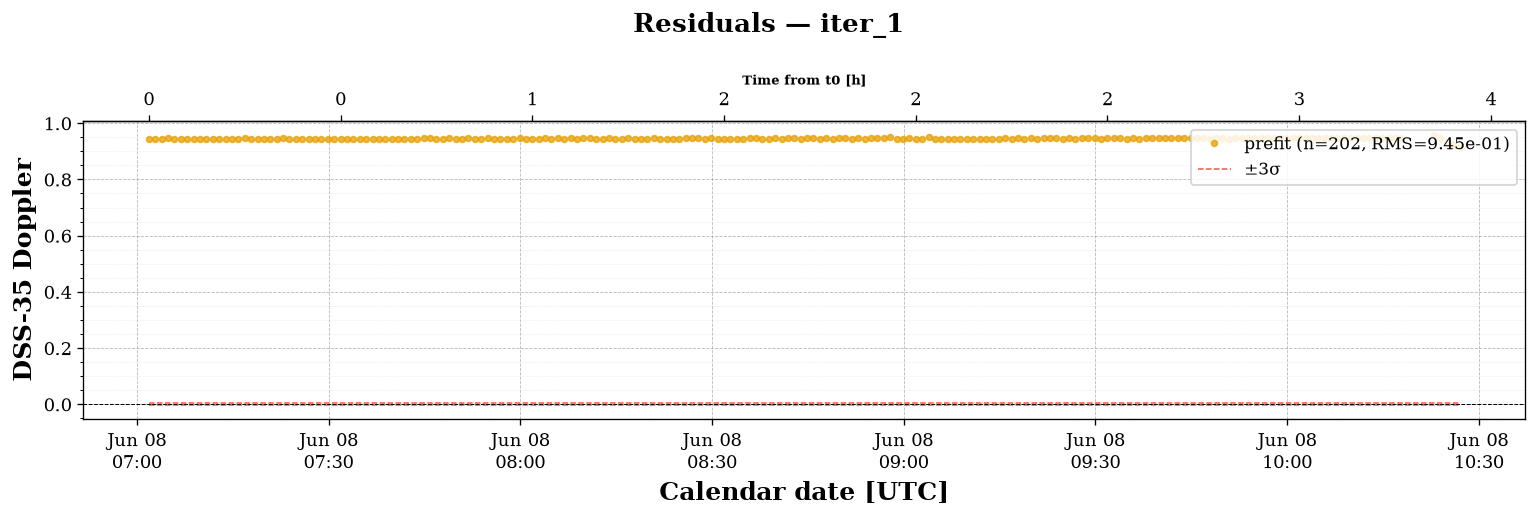

In [12]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="iter_1", kind="prefit", time_unit="hr");

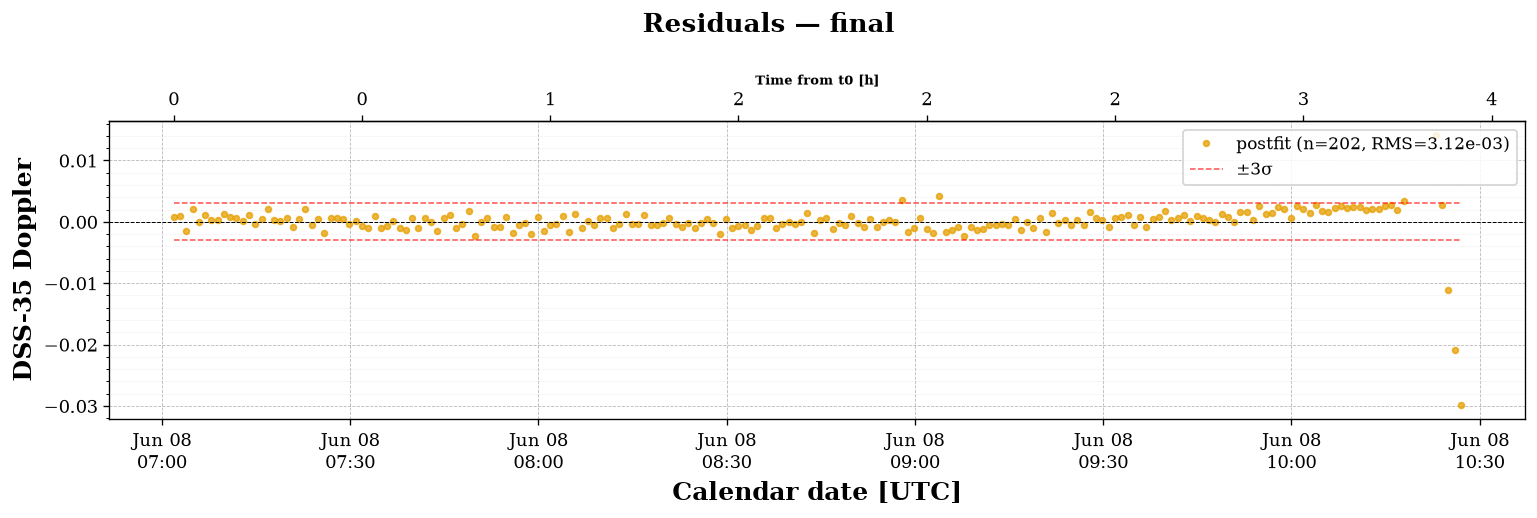

In [13]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="final", kind="postfit", time_unit="hr");

Before the fit, every Doppler residual sits near 0.94 Hz: the a-priori velocity error along the line of sight (−16.9 mm/s; 1 Hz is about 18 mm/s). After the fit, the residuals stay within ±3σ (±3 mHz) for most of the pass, with a slow trend in its second half and the end-of-pass points of section 4 at −10 to −30 mHz; those last points are most of the 3 mHz RMS.

The fit converges in three iterations and reduces the line-of-sight velocity error, the component Doppler measures best, from about 17 mm/s to about 1 mm/s, within 2σ of its formal uncertainty. The position is another matter: one five-hour Doppler pass constrains it only weakly, and the estimate moves from 17 km to 58 km off the flight reconstruction, still within 2σ of a formal uncertainty of 33 km. The post-fit residuals, about 3 mHz RMS, are three times the assumed σ of 1 mHz, so the data weights are optimistic; realistic weights and more passes are the next steps.

With Scarabaeus 1.x this fit diverged: the `DopplerReal` partials were 2.35 times too small, so each iteration overshot, while the linearized post-fit residuals still looked perfect. Comparing the estimate with an independent trajectory, as chapters [6](06_first_od_solution.ipynb)–[8](08_estimating_more.ipynb) did with the truth, is what exposed it: residuals alone cannot reveal an inconsistent measurement model.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Real Doppler and ranging | `DopplerReal`, `SequentialRangingReal` with `computed_measurements_dict` (auxiliary data) |
| Reading DSN observables | `observed_measurements(file, meas_name="2W_doppler" / "2W_sranging", units=...)` |
| Media corrections | `MediaCorrections(tropo_seasonal_file_path=...)`, `find_tro_metadata`, `find_ion_metadata` |
| Coarse editing | `ObsData.meas_outliers`, `ObsData._replace(...)` |
| Residuals of the fit | `SolutionOD.save(path)`, `Plotting.plot_residuals_json(path, iteration=..., kind=...)` |
| Model validation | `computed_measurements` on a reference trajectory, `residuals` |

The pipeline from chapters [4](04_filter_dynamics.ipynb)–[6](06_first_od_solution.ipynb) is unchanged with real data; what changes is the measurement model and the care the data need. Ranging still needs its offset explained before it can join the fit.

→ *How-tos: Media corrections & ramp tables* for the details of the delay models.